# Chatbot generativo en español con Seq2Seq

**Alberto Aragón Jiménez** · Ingeniería Informática (Computación y Sistemas Inteligentes), Universidad de Granada

En este notebook recorro el proyecto paso a paso: cómo está organizado el dataset, cómo se prepara el texto, cómo es el modelo, cómo se entrena la versión final y qué ha servido realmente para mejorarlo.

El punto de partida fue el chatbot Seq2Seq con LSTM que hice como práctica final de Aprendizaje Automático. Respondía bien a las frases que había visto, pero en cuanto la pregunta se formulaba con otras palabras casi siempre fallaba. Aquí intento arreglar eso con dos mejoras:

- **Atención**: que el decoder pueda volver a mirar las palabras de la pregunta en cada paso.
- **Embeddings preentrenados en español**: que el modelo sepa ya qué palabras se parecen entre sí, aunque no las haya visto en entrenamiento.

El código está en `src/chatbot/`. Este notebook lo usa y explica cada resultado.

In [1]:
import os
import sys
import warnings

# Ocultamos los mensajes internos de TensorFlow para que las salidas se lean mejor.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

# El código del proyecto está en ../src
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from chatbot.data import cargar_intenciones, pares, aumentar, respuestas_validas
from chatbot.text import tokenizar
from chatbot.vocab import vocabulario_encoder, vocabulario_decoder, VocabularioPreentrenado
from chatbot.bot import Chatbot

print("Librerías cargadas.")

Librerías cargadas.


## 1. El dataset

### 1.1. Intenciones

El dataset está organizado por **intenciones**: saludar, despedirse, preguntar la hora, preguntar qué es el encoder... Cada intención tiene una o varias respuestas válidas y muchas formas de preguntar lo mismo.

Las frases de cada intención están repartidas en cuatro grupos:

- **train**: frases para entrenar.
- **val**: una frase por intención, para decidir cuándo parar el entrenamiento y qué versión me quedo.
- **test**: tres frases por intención que el modelo no ve nunca, pero que comparten alguna palabra clave con las de entrenamiento.
- **hard**: dos frases por intención **sin ninguna palabra importante en común** con las de entrenamiento. Es la prueba difícil: solo se puede acertar si el modelo entiende el significado.

In [2]:
intenciones = cargar_intenciones()

# Contamos cuántas frases hay en cada grupo.
conteo = {}
for grupo in ["train", "val", "test", "hard"]:
    conteo[grupo] = sum(len(datos[grupo]) for datos in intenciones.values())

print("Intenciones:", len(intenciones))
print("Frases por grupo:", conteo)
print("\nNombres de las intenciones:")
print(list(intenciones))

Intenciones: 24
Frases por grupo: {'train': 162, 'val': 24, 'test': 72, 'hard': 48}

Nombres de las intenciones:
['saludo', 'buenos_dias', 'buenas_noches', 'estado', 'hora', 'despedida', 'identidad', 'actividad', 'gracias', 'ayuda', 'no_entiendo', 'chiste', 'edad', 'tiempo', 'funcionamiento', 'entrenamiento', 'limitaciones', 'seq2seq', 'encoder', 'decoder', 'lstm', 'atencion', 'embedding', 'sobreajuste']


Hay 24 intenciones: 162 frases para entrenar, 24 de validación (una por intención), 72 de test (tres por intención) y 48 de hard (dos por intención).

Las intenciones son de dos tipos: charla normal (saludo, hora, tiempo, chistes...) y preguntas sobre cómo funciona el propio chatbot (encoder, decoder, LSTM, atención, embeddings, sobreajuste).

In [3]:
# Ejemplo completo de una intención.
ejemplo = intenciones["ayuda"]

print("Respuestas válidas:", ejemplo["responses"])
for grupo in ["train", "val", "test", "hard"]:
    print(f"{grupo:5} -> {ejemplo[grupo]}")

Respuestas válidas: ['Dime que necesitas', 'Si, dime tu pregunta']
train -> ['¿Me ayudas?', 'Necesito ayuda', 'Puedes ayudarme', 'Tengo una pregunta', 'Ayuda por favor', 'Tengo una duda', 'Me puedes ayudar']
val   -> ['Necesito que me ayudes']
test  -> ['¿Me puedes ayudar con algo?', 'Tengo otra pregunta', 'Ayúdame']
hard  -> ['Me echas una mano', 'Quería consultarte algo']


En la intención `ayuda` se ve muy bien la diferencia entre los grupos. Las frases de test (`¿Me puedes ayudar con algo?`) comparten palabras con las de entrenamiento (`Me puedes ayudar`). En cambio, `Me echas una mano` no tiene ninguna palabra en común con `Necesito ayuda` o `Puedes ayudarme`: para acertarla, el modelo tiene que saber que significan lo mismo.

Además, esta intención tiene dos respuestas válidas. Al evaluar, cualquiera de las dos cuenta como correcta.

### 1.2. Comprobación de que las frases `hard` no comparten palabras

Para que el grupo `hard` mida de verdad lo que quiero, compruebo que ninguna de sus frases comparte palabras importantes con las de entrenamiento de su intención. Las palabras muy frecuentes (`que`, `el`, `me`...) no cuentan.

In [4]:
# Palabras muy frecuentes que no aportan significado.
palabras_vacias = {"el", "la", "los", "las", "un", "una", "de", "del", "que", "a", "en", "y", "o",
                   "me", "te", "mi", "tu", "lo", "le", "se", "es", "por", "para", "con", "al",
                   "hay", "ya", "muy", "como", "cual", "cuando", "donde", "quien", "eres", "has",
                   "este", "esta", "estas", "estos", "eso", "esto", "son", "soy", "sabes"}

frases_con_coincidencias = 0

for nombre, datos in intenciones.items():
    # Palabras que aparecen en el entrenamiento de esta intención.
    palabras_train = {t for frase in datos["train"] for t in tokenizar(frase)}

    for frase in datos["hard"]:
        comunes = [t for t in tokenizar(frase) if t in palabras_train and t not in palabras_vacias]
        if comunes:
            frases_con_coincidencias += 1
            print(f"{nombre}: '{frase}' comparte {comunes}")

print("Frases hard que comparten palabras importantes:", frases_con_coincidencias)

Frases hard que comparten palabras importantes: 0


Ninguna frase de `hard` comparte palabras importantes con el entrenamiento de su intención. Al montar el dataset había dos que sí lo hacían (`tal` y `modelo`) y las cambié por otras.

## 2. Preparación del texto

### 2.1. Limpieza y tokenización

Es el mismo preprocesado de la primera versión: todo a minúsculas, sin tildes y sin signos de puntuación, y después se separa en palabras.

In [5]:
for frase in ["¿Cómo estás?", "Me explicas la atención, por favor", "¡¡Buenos días!!"]:
    print(f"{frase!r:40} -> {tokenizar(frase)}")

'¿Cómo estás?'                           -> ['como', 'estas']
'Me explicas la atención, por favor'     -> ['me', 'explicas', 'la', 'atencion', 'por', 'favor']
'¡¡Buenos días!!'                        -> ['buenos', 'dias']


Las tres frases quedan limpias: `¿Cómo estás?` pasa a ser `['como', 'estas']`. Así el modelo no tiene que aprender por separado `Cómo`, `cómo` y `como`, que para este problema son la misma palabra.

### 2.2. Aumento de datos

Con 162 frases de entrenamiento el modelo tiene muy pocos ejemplos. Por eso aplico el mismo **aumento de datos** de la primera versión: de cada frase saco tres copias, y a cada copia le hago uno de estos cambios al azar:

- poner una muletilla delante (`oye`, `perdona`, `una pregunta`...),
- poner una coletilla detrás (`por favor`, `porfa`...),
- o quitarle una palabra.

In [6]:
pares_train_originales = pares(intenciones, "train")
train = aumentar(pares_train_originales, n_copias=3)

val = pares(intenciones, "val")
test = pares(intenciones, "test")
hard = pares(intenciones, "hard")

print("Frases de entrenamiento antes del aumento:", len(pares_train_originales))
print("Frases de entrenamiento después del aumento:", len(train))

# Las copias nuevas van detrás de las originales.
print("\nEjemplos de frases nuevas:")
for frase, respuesta, intencion in train[len(pares_train_originales):len(pares_train_originales) + 8]:
    print(f"  {frase!r:30} -> {intencion}")

Frases de entrenamiento antes del aumento: 162
Frases de entrenamiento después del aumento: 648

Ejemplos de frases nuevas:
  'hola chatbot'                 -> saludo
  'perdona hola'                 -> saludo
  'hola'                         -> saludo
  'hola amigo chatbot'           -> saludo
  'hola amigo chatbot'           -> saludo
  'hola amigo porfa'             -> saludo
  'hola buenas'                  -> saludo
  'perdona buenas'               -> saludo


Se pasa de 162 a 648 frases de entrenamiento. Algunas copias salen repetidas (por ejemplo `hola amigo chatbot` aparece dos veces), pero no es un problema: simplemente esa frase pesa un poco más.

El aumento solo se aplica al entrenamiento. Las frases de validación, test y hard se quedan tal cual, porque son las que uso para medir.

## 3. Vocabularios y embeddings

La red no trabaja con palabras sino con números: cada palabra se cambia por su índice en un vocabulario. Aquí está la primera mejora importante.

### 3.1. Vocabulario de la primera versión

En la primera versión el vocabulario del encoder eran solo las palabras que aparecen en las preguntas de entrenamiento. Cada palabra empezaba con un vector aleatorio que el modelo iba aprendiendo, y cualquier palabra nueva se convertía en `<unk>` (desconocida).

In [7]:
vocab_base = vocabulario_encoder(train)
vocab_respuestas = vocabulario_decoder(train)

print("Palabras en el vocabulario del encoder:", len(vocab_base))
print("Palabras en el vocabulario del decoder:", len(vocab_respuestas))

# Una frase con palabras que nunca aparecen en entrenamiento.
frase = "Define el encoder"
print("\nFrase:", frase)
print("Tokens:", tokenizar(frase))
print("Índices:", vocab_base.codificar(frase), "  (1 = <unk>)")

Palabras en el vocabulario del encoder: 174
Palabras en el vocabulario del decoder: 93

Frase: Define el encoder
Tokens: ['define', 'el', 'encoder']
Índices: [1, 53, 57]   (1 = <unk>)


El vocabulario del encoder tiene solo 174 palabras. En la frase de prueba, `define` no aparece en ninguna pregunta de entrenamiento, así que se convierte en el índice 1 (`<unk>`). Para el modelo es como si esa palabra no existiera, y solo le queda `el encoder` para adivinar la respuesta.

### 3.2. Vocabulario con embeddings preentrenados

En la versión mejorada el encoder usa los vectores de spaCy (`es_core_news_md`), que están entrenados con millones de textos en español. Cada palabra tiene un vector de 300 números, y palabras con significado parecido tienen vectores parecidos.

Estos vectores se dejan **congelados** (no se entrenan). Si se ajustaran, el modelo solo movería las palabras que aparecen en los datos, y las palabras nuevas dejarían de estar cerca de ellas, que es justo lo que quiero aprovechar.

In [8]:
vocab = VocabularioPreentrenado(pares_train_originales)

print("Palabras en el vocabulario del encoder:", f"{len(vocab.stoi):,}")
print("Tamaño de la matriz de embeddings:", vocab.matriz.shape)
print("Palabras de entrenamiento que spaCy no conoce:", vocab.palabras_extra)

print("\nÍndices de 'Define el encoder':", vocab.codificar("Define el encoder"))

Palabras en el vocabulario del encoder: 351,492
Tamaño de la matriz de embeddings: (20010, 300)
Palabras de entrenamiento que spaCy no conoce: 8

Índices de 'Define el encoder': [3747, 10, 12465]


Ahora el vocabulario tiene más de 350.000 palabras y `define` ya tiene su propio índice. La matriz tiene unas 20.000 filas porque spaCy comparte un mismo vector entre palabras muy parecidas (por ejemplo, formas de un mismo verbo).

Solo 8 palabras de entrenamiento no están en spaCy (como `seq2seq` o `lstm`). A esas les doy un vector aleatorio propio para que el modelo pueda distinguirlas.

In [9]:
# ¿A qué palabras de entrenamiento se parecen algunas palabras que el chatbot nunca ha visto?
palabras_train = sorted({t for frase, _, _ in pares_train_originales for t in tokenizar(frase)})

for nueva in ["define", "aprendes", "chistes", "tormenta"]:
    vector_nueva = vocab.matriz[vocab.stoi[nueva]]

    # Como los vectores miden 1, el producto escalar es la similitud coseno.
    similitudes = {}
    for palabra in palabras_train:
        if palabra != nueva:
            similitudes[palabra] = float(vocab.matriz[vocab.stoi[palabra]] @ vector_nueva)

    mas_parecidas = sorted(similitudes, key=similitudes.get, reverse=True)[:4]
    print(f"{nueva:10} -> {mas_parecidas}")

define     -> ['explicas', 'significa', 'funciona', 'explicame']
aprendes   -> ['aprender', 'aprendiste', 'aprendido', 'sabes']
chistes    -> ['chiste', 'reir', 'dices', 'hablar']
tormenta   -> ['llover', 'noche', 'frio', 'llamas']


Ninguna de estas cuatro palabras aparece en las frases de entrenamiento, pero sus vectores están muy cerca de palabras que sí aparecen:

- `define` se parece a `explicas`, `significa` y `explícame`: justo las palabras de las preguntas de tipo "¿qué es...?".
- `aprendes` se parece a `aprender` y `aprendiste`.
- `chistes` a `chiste`, y `tormenta` a `llover`.

Esto es lo que permite al modelo entender preguntas que no ha visto: para él, `define` ya no es `<unk>`, sino algo muy parecido a `explícame`.

### 3.3. Cómo quedan los datos para el modelo

Igual que en la primera versión, cada par pregunta-respuesta se convierte en tres secuencias de índices:

- **entrada del encoder**: la pregunta;
- **entrada del decoder**: la respuesta empezando por `<start>`;
- **salida esperada del decoder**: la respuesta terminando en `<end>`.

Todas se rellenan con `<pad>` (índice 0) hasta la misma longitud.

In [10]:
bot_prueba = Chatbot(preentrenado=False)
bot_prueba.vocab_enc = vocab_base
bot_prueba.vocab_dec = vocab_respuestas
bot_prueba.max_encoder = max(len(tokenizar(f)) for f, _, _ in train) + 2
bot_prueba.max_decoder = max(len(tokenizar(r)) for _, r, _ in train) + 1

X_enc, X_dec, Y = bot_prueba._codificar_pares(train[:1])

print("Pregunta:  ", train[0][0], "->", X_enc[0])
print("Respuesta: ", train[0][1])
print("Entrada del decoder:", X_dec[0])
print("Salida del decoder: ", Y[0])
print("\nLongitud máxima del encoder:", bot_prueba.max_encoder)
print("Longitud máxima del decoder:", bot_prueba.max_decoder)

Pregunta:   Hola -> [89  0  0  0  0  0  0  0  0]
Respuesta:  Hola, en que puedo ayudarte
Entrada del decoder: [ 1 41 23 69 68  7  0  0]
Salida del decoder:  [41 23 69 68  7  2  0  0]

Longitud máxima del encoder: 9
Longitud máxima del decoder: 8


La pregunta `Hola` queda como un solo índice seguido de ceros. En la respuesta se ve el desplazamiento: la entrada del decoder empieza por `1` (`<start>`) y la salida esperada es la misma respuesta adelantada una posición y terminada en `2` (`<end>`). Así, en cada paso el decoder aprende a predecir la palabra siguiente.

Las preguntas se rellenan hasta 9 palabras: la más larga de entrenamiento más un margen de dos, por si el usuario escribe algo un poco más largo.

## 4. El modelo

La arquitectura es la misma de la primera versión, con las dos mejoras activadas:

1. **Encoder**: Embedding (los vectores de spaCy, congelados) + LSTM de 128 unidades. Lee la pregunta y la resume.
2. **Decoder**: Embedding de 64 + LSTM de 128 unidades que empieza con los estados finales del encoder.
3. **Atención**: en cada paso, el decoder compara su salida con la salida del encoder en cada palabra de la pregunta y hace una media ponderada (el *contexto*). Ese contexto se junta con la salida del decoder antes de la capa final.
4. **Capa final**: Dense con softmax sobre las palabras de las respuestas.

In [11]:
bot = Chatbot(atencion=True, preentrenado=True, semilla=0)
bot.entrenar(train, val)

# Resumen de las capas: nombre, tipo, forma de la salida y número de parámetros.
for capa in bot.modelo.layers:
    if capa.count_params() > 0:
        print(f"{capa.name:14} {type(capa).__name__:10} {capa.count_params():>10,}")

total = bot.modelo.count_params()
entrenables = bot.n_parametros()
print(f"\nParámetros totales:      {total:>10,}")
print(f"Parámetros entrenables:  {entrenables:>10,}")
print(f"Parámetros congelados:   {total - entrenables:>10,}")

emb_encoder    Embedding   6,003,000
emb_decoder    Embedding       5,952
lstm_encoder   LSTM          219,648
lstm_decoder   LSTM           98,816
combinar       Dense          32,896
softmax        Dense          11,997

Parámetros totales:       6,372,309
Parámetros entrenables:     369,309
Parámetros congelados:    6,003,000


El modelo tiene unos 6,4 millones de parámetros, pero casi todos son los vectores de spaCy del `emb_encoder` (20.010 filas × 300 números = 6.003.000), que están congelados.

El modelo solo entrena unos 370.000 parámetros: las dos LSTM, el embedding del decoder, la capa `combinar` (que junta la salida del decoder con el contexto de la atención) y la `softmax` final. Es un modelo pequeño, y por eso se entrena en menos de un minuto en CPU.

### 4.1. Entrenamiento

Se entrena con Adam, dropout de 0.2 en las LSTM y lotes de 8 frases. Para no tener que adivinar el número de épocas uso **early stopping**: el entrenamiento se para cuando la pérdida de validación lleva 25 épocas sin mejorar, y se recuperan los pesos de la mejor época.

Épocas entrenadas: 43
Mejor pérdida de validación: 0.191
Parámetros entrenables: 369,309


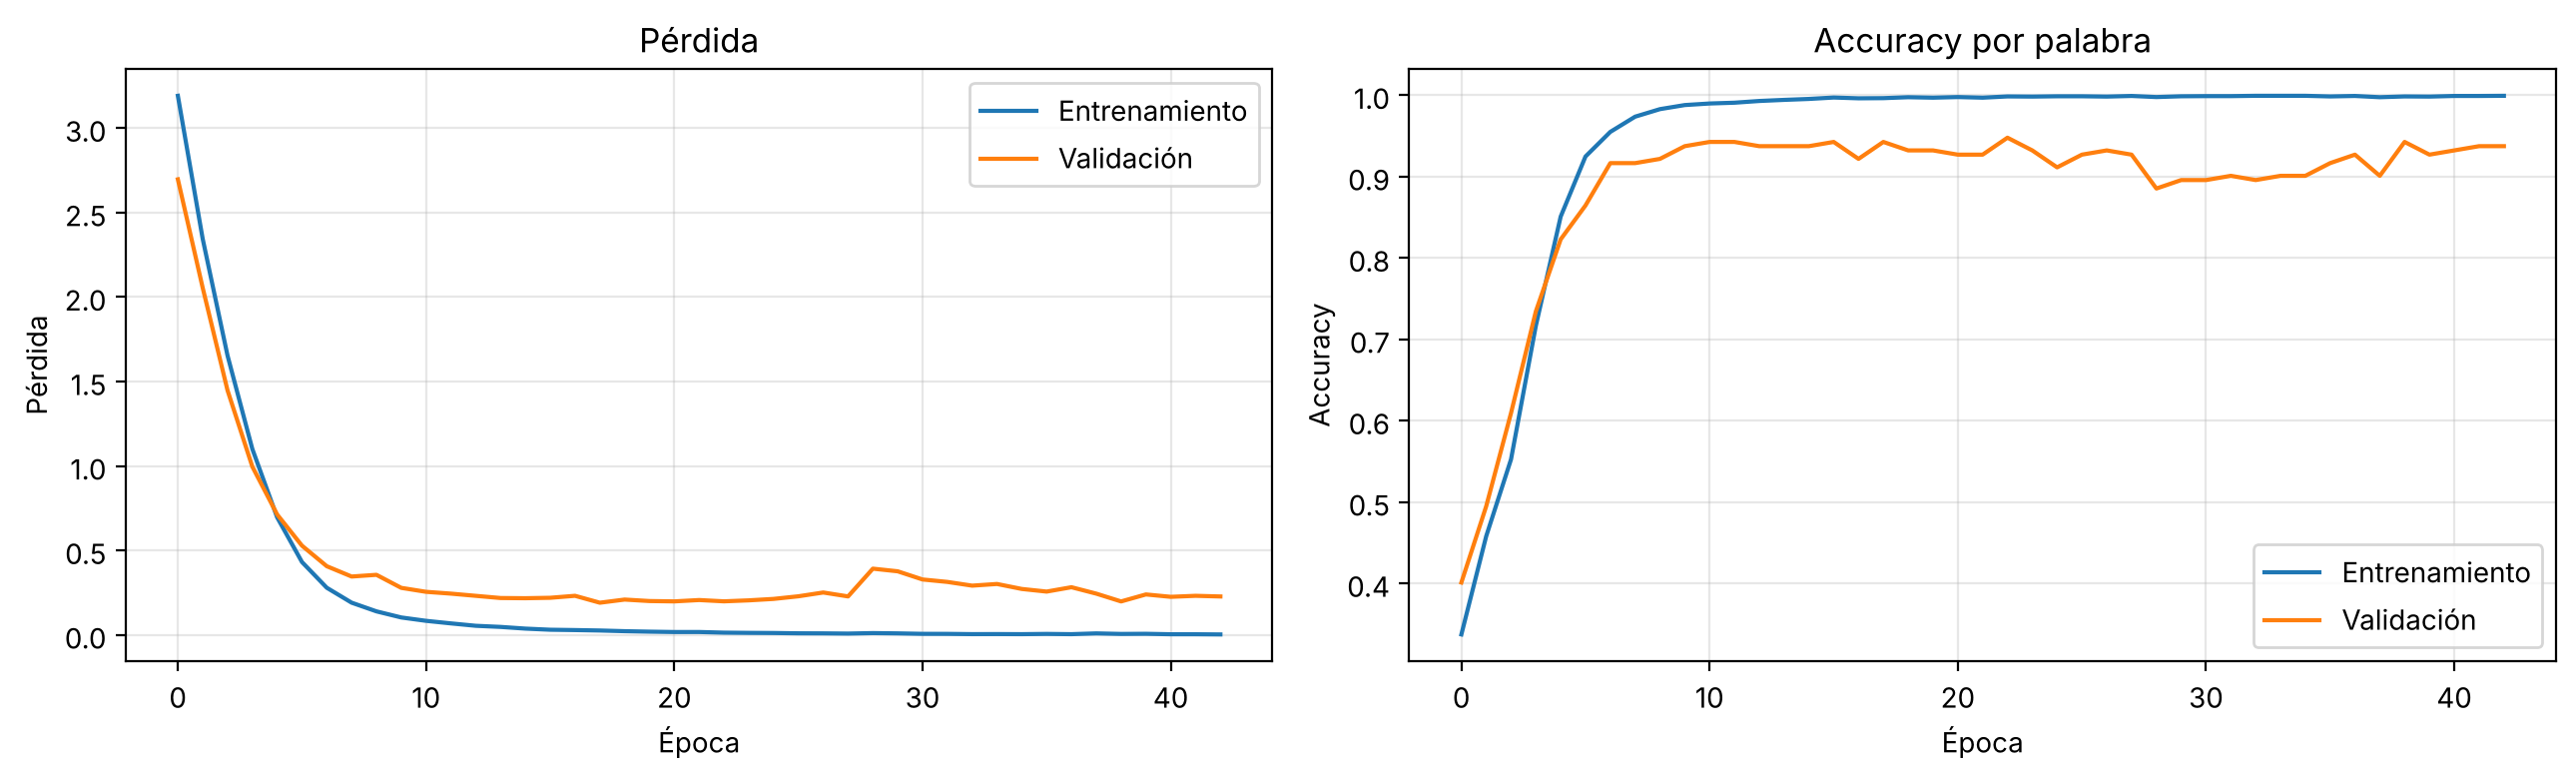

In [12]:
print("Épocas entrenadas:", len(bot.historial["loss"]))
print("Mejor pérdida de validación:", round(min(bot.historial["val_loss"]), 3))
print("Parámetros entrenables:", f"{bot.n_parametros():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Evolución de la pérdida.
axes[0].plot(bot.historial["loss"], label="Entrenamiento")
axes[0].plot(bot.historial["val_loss"], label="Validación")
axes[0].set_title("Pérdida")
axes[0].set_ylabel("Pérdida")

# Evolución de la precisión.
axes[1].plot(bot.historial["accuracy"], label="Entrenamiento")
axes[1].plot(bot.historial["val_accuracy"], label="Validación")
axes[1].set_title("Accuracy por palabra")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

La pérdida de validación baja junto con la de entrenamiento durante las primeras épocas y después se estabiliza. En ese punto el modelo ya no mejora con frases nuevas y solo seguiría memorizando, así que el early stopping corta el entrenamiento y recupera la mejor época.

Es muy distinto de la primera versión, donde la pérdida de validación subía sin parar desde el principio.

Hay que tener en cuenta que esta accuracy es **por palabra** generada. La métrica que importa de verdad es si la respuesta entera es correcta, que es lo que mido a continuación.

## 5. Evaluación de la versión final

Una respuesta cuenta como **correcta** solo si coincide palabra por palabra con alguna de las respuestas válidas de su intención. Es una métrica estricta: una sola palabra distinta ya cuenta como fallo.

In [13]:
validas = respuestas_validas(intenciones)


def evaluar(bot, lista):
    # Genera la respuesta de cada frase y comprueba si es una de las válidas.
    respuestas = bot.responder_lote([frase for frase, _, _ in lista])

    filas = []
    for (frase, _, intencion), respuesta in zip(lista, respuestas):
        filas.append({
            "Frase": frase,
            "Intención": intencion,
            "Respuesta": respuesta,
            "Correcta": respuesta in validas[intencion],
        })
    return pd.DataFrame(filas)


res_test = evaluar(bot, test)
res_hard = evaluar(bot, hard)

print(f"Test: {res_test.Correcta.sum()} de {len(res_test)} correctas ({res_test.Correcta.mean():.0%})")
print(f"Hard: {res_hard.Correcta.sum()} de {len(res_hard)} correctas ({res_hard.Correcta.mean():.0%})")

Test: 65 de 72 correctas (90%)
Hard: 7 de 48 correctas (15%)


Con esta semilla, el modelo acierta 65 de las 72 frases de test (90 %), pero solo 7 de las 48 de `hard` (15 %). La diferencia entre los dos grupos es enorme, y es justo lo que esperaba: en test casi siempre hay una palabra clave que ayuda, y en `hard` no.

Veamos qué frases de `hard` acierta:

In [14]:
display(res_hard[res_hard.Correcta])

,Frase,Intención,Respuesta,Correcta
7,¿Cómo lo llevas?,estado,estoy funcionando correctamente,True
15,¿En qué trabajas?,actividad,aprendiendo a hablar,True
19,Quería consultarte algo,ayuda,si dime tu pregunta,True
28,¿De qué estás construido?,funcionamiento,uso una red seq2seq con lstm,True
31,¿Quién te enseñó?,entrenamiento,aprendi con ejemplos de preguntas y respuestas,True
45,¿Cómo pasas el texto a números?,embedding,convierte cada palabra en un vector,True
47,¿Por qué aprender de memoria es malo?,sobreajuste,es memorizar en vez de generalizar,True


Algunos aciertos se explican claramente por los embeddings. Por ejemplo, `¿De qué estás construido?` no comparte ninguna palabra con las frases de entrenamiento de su intención, pero `construido` está cerca de `hecho` y `arquitectura` (*¿Cómo estás hecho?*, *¿Qué arquitectura tienes?*), y el modelo responde bien.

Y algunos de los fallos:

In [15]:
# Fallos de algunas intenciones de charla.
fallos = res_hard[~res_hard.Correcta]
display(fallos[fallos["Intención"].isin(["despedida", "gracias", "ayuda", "no_entiendo"])])

,Frase,Intención,Respuesta,Correcta
10,Me marcho ya,despedida,que descanses,False
11,Tengo que irme,despedida,que descanses,False
16,Eres un crack,gracias,soy un chatbot generativo,False
17,Me has salvado,gracias,dime que necesitas,False
18,Me echas una mano,ayuda,que descanses,False
20,Estoy perdido,no_entiendo,hasta la vista,False
21,Me he liado,no_entiendo,dime que necesitas,False


En los fallos se ve el límite del modelo. `Me echas una mano` recibe `que descanses` y `Estoy perdido` recibe `hasta la vista`: en la primera, ninguna palabra se parece a `ayuda`, y la expresión completa solo tiene sentido como frase hecha. Los vectores de palabras sueltas no saben que *echar una mano* significa *ayudar*.

Muchas respuestas equivocadas son, eso sí, frases completas y bien formadas de otra intención: el decoder ha aprendido bien a generar, el problema está en entender la pregunta.

## 6. ¿Qué mejora ha servido?

Una sola ejecución puede engañar: con tan pocos datos, dos entrenamientos del mismo modelo con semillas distintas pueden diferir varios puntos. Por eso cada versión se entrena **cinco veces con semillas distintas** (`python -m chatbot.experiments`) y comparo las medias.

También incluyo una referencia que no genera texto: hacer la media de los vectores de spaCy de la frase y devolver la respuesta de la frase de entrenamiento más parecida.

In [16]:
metricas = pd.read_csv("../results/metrics.csv")

tabla = metricas.groupby("version", sort=False)[["acierto_val", "acierto_test", "acierto_hard", "epocas"]].mean()
desviacion = metricas.groupby("version", sort=False)[["acierto_test", "acierto_hard"]].std()

resumen = pd.DataFrame({
    "Validación": (tabla.acierto_val * 100).round(0),
    "Test": (tabla.acierto_test * 100).round(1),
    "± test": (desviacion.acierto_test * 100).round(1),
    "Hard": (tabla.acierto_hard * 100).round(1),
    "± hard": (desviacion.acierto_hard * 100).round(1),
    "Épocas": tabla.epocas.round(0),
})
display(resumen)

,Validación,Test,± test,Hard,± hard,Épocas
version,,,,,,
retrieval_baseline,71.0,69.4,NaN,8.3,NaN,0.0
seq2seq,72.0,80.3,1.5,10.8,1.7,49.0
seq2seq_attention,78.0,76.9,3.6,10.0,2.7,59.0
seq2seq_pretrained,75.0,95.6,1.8,15.8,1.9,53.0
seq2seq_attention_pretrained,85.0,93.3,2.8,12.5,4.7,80.0


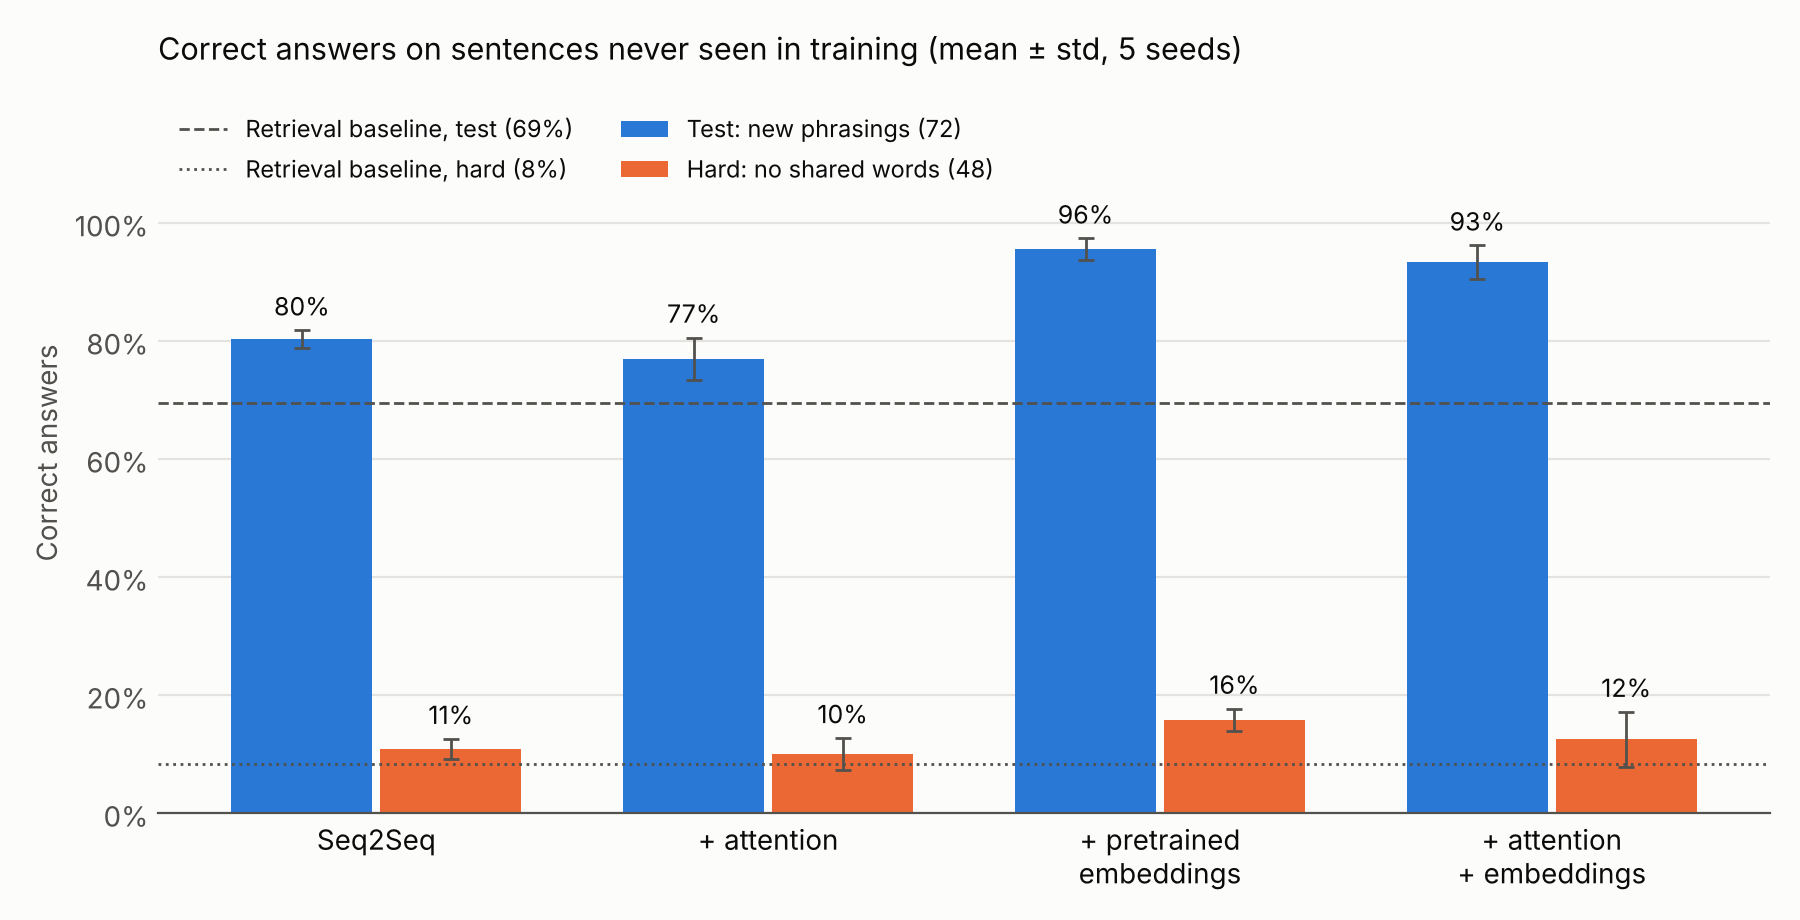

In [17]:
display(Image("../figures/results.png", width=800))

Lo que dicen los números:

- **Los embeddings preentrenados son la mejora que funciona.** En test el acierto pasa del 80 % al 96 %, con los mismos datos y casi la misma arquitectura. La diferencia es mucho mayor que la variación entre semillas (± 2 puntos), así que no es casualidad.
- **La atención no mejora el acierto.** Las preguntas tienen entre 3 y 6 palabras y la respuesta depende de una o dos palabras clave, así que los estados finales de la LSTM ya bastan para resumirlas. La atención está pensada para frases largas, como en traducción.
- **La versión final la elegí con validación**: atención + embeddings tiene el mejor resultado en validación (85 %). En test la versión sin atención acierta algo más (96 % frente a 93 %), pero con 24 frases de validación esa diferencia está dentro del ruido. No cambio la elección mirando el test, porque entonces el test dejaría de ser una medida honesta.
- **Las frases `hard` siguen siendo muy difíciles**: como mucho un 16 %. Los embeddings ayudan algo (del 11 % al 16 %), pero no lo suficiente.
- **Generar es mejor que buscar la frase más parecida**: la referencia se queda en el 69 % en test. Al hacer la media de todos los vectores de la frase, las muletillas pesan igual que la palabra clave y se pierde información.

In [18]:
# Frases de test que el Seq2Seq base falla casi siempre y la versión con embeddings acierta.
predicciones = pd.read_csv("../results/predictions.csv")
test_pred = predicciones[predicciones.split == "test"]

# Porcentaje de las 5 semillas en que cada versión acierta cada frase.
por_frase = test_pred.pivot_table(index="frase", columns="version", values="correcta", aggfunc="mean")
arregladas = por_frase[(por_frase.seq2seq < 0.5) & (por_frase.seq2seq_pretrained >= 0.8)]

display(arregladas[["seq2seq", "seq2seq_pretrained"]].rename(
    columns={"seq2seq": "Base", "seq2seq_pretrained": "Con embeddings"}))

version,Base,Con embeddings
frase,,
Define atención,0.0,1.0
Define embedding,0.0,1.0
Dime algo gracioso,0.0,0.8
Me explicas Seq2Seq,0.0,1.0
Me explicas el decoder,0.4,1.0
Me explicas el encoder,0.2,1.0
Me explicas el sobreajuste,0.0,1.0
Me explicas la atención,0.2,1.0
Me explicas qué es LSTM,0.0,1.0


Esta tabla explica de dónde sale la mejora. Las frases que pasan de fallarse casi siempre a acertarse son de dos tipos:

- Frases con una palabra que la versión base no había visto nunca: `Define atención`, `¿Cómo aprendes?`, `Dime algo gracioso`. Para la versión base esas palabras eran `<unk>`.
- Frases con `Me explicas...`. Aquí la palabra sí estaba en entrenamiento, pero solo en *Me lo explicas*, de la intención "no entiendo". La versión base asociaba `me explicas` con esa intención y respondía `puedo explicarlo paso a paso` aunque la pregunta fuera sobre el encoder. Con los embeddings el modelo se fija más en la palabra clave (`encoder`, `atención`...) y acierta.

## 7. Dónde mira la atención

Aunque la atención no mejore el acierto, tiene una ventaja: permite ver en qué palabras de la pregunta se fija el modelo al escribir cada palabra de la respuesta.

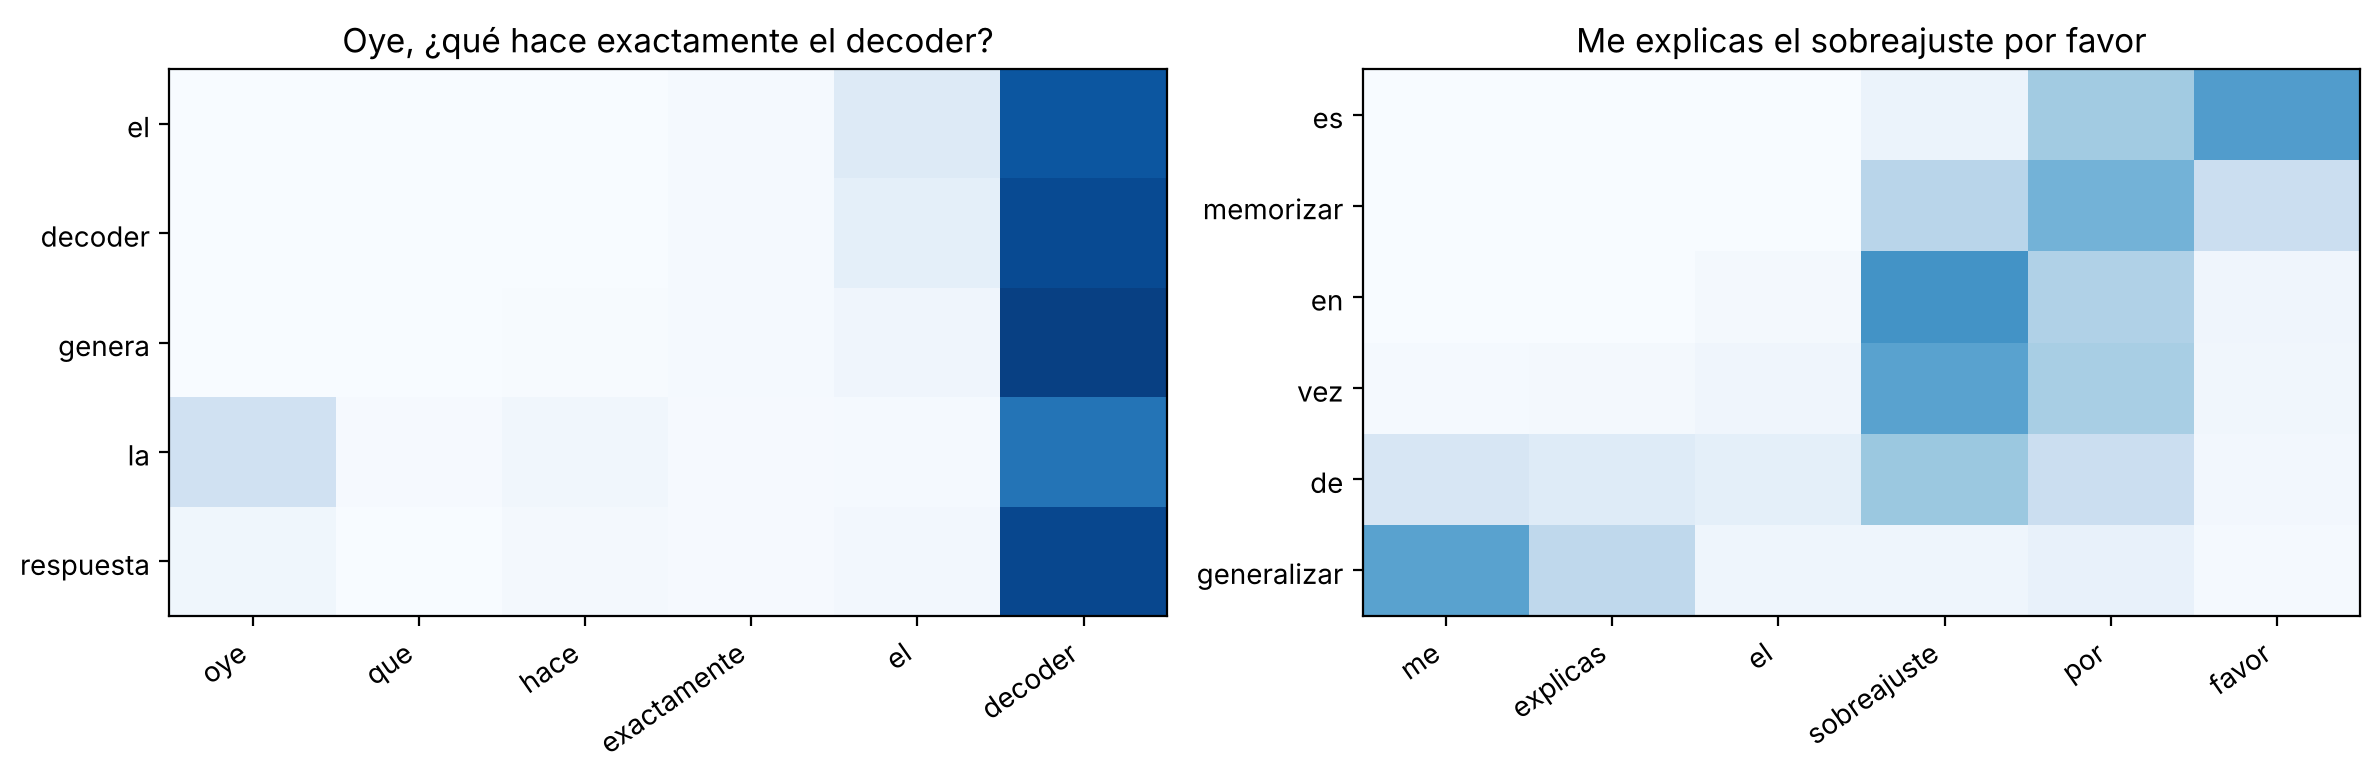

In [19]:
frases_ejemplo = ["Oye, ¿qué hace exactamente el decoder?", "Me explicas el sobreajuste por favor"]
respuestas, pesos = bot.responder_lote(frases_ejemplo, devolver_atencion=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, frase, respuesta, p in zip(axes, frases_ejemplo, respuestas, pesos):
    palabras_pregunta = tokenizar(frase)
    palabras_respuesta = respuesta.split()

    # Filas: palabras de la respuesta. Columnas: palabras de la pregunta.
    matriz = p[:len(palabras_respuesta), :len(palabras_pregunta)]
    ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1, aspect="auto")

    ax.set_xticks(range(len(palabras_pregunta)), palabras_pregunta, rotation=35, ha="right")
    ax.set_yticks(range(len(palabras_respuesta)), palabras_respuesta)
    ax.set_title(frase)

plt.tight_layout()
plt.show()

Cuanto más oscura es una casilla, más se fija el decoder en esa palabra de la pregunta al escribir esa palabra de la respuesta.

En la primera pregunta el modelo ignora `oye`, `que`, `hace` y `exactamente` y se fija casi solo en `decoder`, que es la única palabra que decide la respuesta. En la segunda se reparte entre `sobreajuste` y `por favor`: la coletilla viene del aumento de datos y el modelo ha aprendido a tenerla en cuenta, aunque no aporte significado.

## 8. Prueba libre

Por último, pruebo el chatbot con frases inventadas, como si alguien lo estuviera usando.

In [20]:
frases = [
    "Hola",
    "¿Cómo funcionas?",
    "Me explicas el encoder",
    "¿Qué es el sobreajuste?",
    "Cuéntame un chiste",
    "¿Me echas una mano?",
    "Me marcho ya",
]

for frase, respuesta in zip(frases, bot.responder_lote(frases)):
    print(f"Tú:  {frase}")
    print(f"Bot: {respuesta}\n")

Tú:  Hola
Bot: hola en que puedo ayudarte

Tú:  ¿Cómo funcionas?
Bot: uso un modelo encoder decoder

Tú:  Me explicas el encoder
Bot: el encoder resume la frase de entrada

Tú:  ¿Qué es el sobreajuste?
Bot: es memorizar en vez de generalizar

Tú:  Cuéntame un chiste
Bot: los chistes no son lo mio

Tú:  ¿Me echas una mano?
Bot: que descanses

Tú:  Me marcho ya
Bot: que descanses



Las cinco primeras respuestas son correctas, incluida `Me explicas el encoder`, que la primera versión fallaba. Las dos últimas fallan: `Me echas una mano` por lo que ya he comentado, y `Me marcho ya` porque `marcho` no se parece lo suficiente a `voy` o `adiós` para este modelo (la versión sin atención sí la acertaba en las cinco semillas).

## 9. Conclusiones

- Lo que más ha mejorado el chatbot no ha sido hacer el modelo más complejo, sino **darle conocimiento previo del idioma**: con los mismos datos y casi la misma arquitectura, el acierto en frases nuevas sube del 80 % al 96 %.
- La **atención** no mejora el acierto con frases tan cortas, pero hace el modelo más fácil de interpretar.
- Medir con **varias semillas** y elegir con **validación** ha sido clave para no sacar conclusiones de una ejecución con suerte.
- El límite está en las frases que dicen lo mismo con palabras totalmente distintas (`Me echas una mano`). Para eso no bastan vectores de palabras sueltas: haría falta un modelo que represente **frases completas** (sentence embeddings) o un **Transformer preentrenado** en español.
- Otra mejora clara sería tener **muchos más datos reales**: 162 frases para 24 intenciones es muy poco.